In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import VGG19
from tensorflow.keras.applications.vgg19 import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.cluster import KMeans

In [3]:
DATA_DIR = r"/content/drive/MyDrive/Augmented_tomato_leaves/Images"
TRAIN_DIR = os.path.join(DATA_DIR, "train")
TEST_DIR = os.path.join(DATA_DIR, "val")   # final evaluation only

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

In [4]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

validation_split = 0.375 # 100-60


Found 1000 files belonging to 2 classes.


In [5]:
from sklearn.model_selection import train_test_split

class_names = sorted(os.listdir(TEST_DIR))

image_paths = []
labels = []

for label, class_name in enumerate(class_names):
    class_dir = os.path.join(TEST_DIR, class_name)
    files = os.listdir(class_dir)

    for file in files:
        image_paths.append(os.path.join(class_dir, file))
        labels.append(label)

image_paths = np.array(image_paths)
labels = np.array(labels)

print("Total images:", len(image_paths))

validation_split = 0.375 # 100-60

train_paths, test_paths, train_labels, test_labels = train_test_split(
    image_paths,
    labels,
    test_size=validation_split,
    stratify=labels,
    random_state=SEED
)

# Now train_paths = 100 images (balanced)
# test_paths = 60 images (balanced)

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    return image, label


def make_dataset(paths, labels):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    return ds


val_ds = make_dataset(train_paths, train_labels)
test_ds = make_dataset(test_paths, test_labels)

Total images: 160


In [6]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().shuffle(1000).prefetch(AUTOTUNE)
val_ds = val_ds.cache().prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

In [7]:
def build_model(dense_units, dropout_rate, learning_rate):

    base_model = VGG19(
        weights='imagenet',
        include_top=False,
        input_shape=(224, 224, 3)
    )
    base_model.trainable = False

    inputs = keras.Input(shape=(224, 224, 3))

    x = inputs
    x = preprocess_input(x)
    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dense(dense_units, activation='relu')(x)
    x = layers.Dropout(dropout_rate)(x)

    outputs = layers.Dense(1, activation='sigmoid')(x)

    model = keras.Model(inputs, outputs)

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model

In [8]:
dense_options = [128, 256]
dropout_options = [0.3, 0.4, 0.5]
lr_options = [1e-3, 1e-4]

In [9]:
best_val_acc = 0
best_params = None
best_model = None

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

for dense in dense_options:
    for dropout in dropout_options:
        for lr in lr_options:

            print(f"\nTraining: Dense={dense}, Dropout={dropout}, LR={lr}")

            model = build_model(dense, dropout, lr)

            history = model.fit(
                train_ds,                          # tf.data — prefetch keeps GPU busy
                validation_data=val_ds,
                epochs=10,
                callbacks=early_stop,
                verbose=1
            )

            acc = max(history.history['val_accuracy'])
            print("Validation Accuracy:", acc)

            if acc > best_val_acc:
                best_val_acc = acc
                best_params = (dense, dropout, lr)
                best_model = model


Training: Dense=128, Dropout=0.3, LR=0.001
80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 186s 1s/step - accuracy: 0.7810 - loss: 0.7782 - val_accuracy: 0.7600 - val_loss: 1.1986
Epoch 2/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 7s 222ms/step - accuracy: 0.8910 - loss: 0.3226 - val_accuracy: 0.8500 - val_loss: 0.6325
Epoch 3/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 7s 225ms/step - accuracy: 0.9250 - loss: 0.1822 - val_accuracy: 0.8700 - val_loss: 0.5563
Epoch 4/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 7s 231ms/step - accuracy: 0.9450 - loss: 0.1425 - val_accuracy: 0.8700 - val_loss: 0.5599
Epoch 5/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 8s 238ms/step - accuracy: 0.9480 - loss: 0.1287 - val_accuracy: 0.8300 - val_loss: 0.8092
Epoch 6/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 8s 241ms/step - accuracy: 0.9550 - loss: 0.1085 - val_accuracy: 0.8900 - val_loss: 0.5695
Validation Accuracy: 0.8899999856948853

Training: Dense=128, Dropout=0.3, LR=0.0001
Epoch 1/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 14s 370ms/step 

In [10]:
print("\nBest Validation Accuracy:", best_val_acc)
print("Best Parameters:")
print("Dense Units:", best_params[0])
print("Dropout:", best_params[1])
print("Learning Rate:", best_params[2])


Best Validation Accuracy: 0.8999999761581421
Best Parameters:
Dense Units: 128
Dropout: 0.4
Learning Rate: 0.001


In [11]:
val_ds_2 = val_ds.map(lambda x, y: (x, tf.cast(y, tf.int32)))

combined_ds = train_ds.concatenate(val_ds_2)
combined_ds = combined_ds.shuffle(1000).prefetch(tf.data.AUTOTUNE)

In [12]:
best_model=build_model(best_params[0],best_params[1], best_params[2])
base_model = best_model.layers[1]
base_model.trainable = True

# Freeze early layers, unfreeze last 20 layers
for layer in base_model.layers[:-20]:
    layer.trainable = False

best_model.compile(
    optimizer=keras.optimizers.Adam(1e-5),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

best_model.fit(
    combined_ds,                          # tf.data — prefetch keeps GPU busy
    epochs=40,
    callbacks=early_stop,
    verbose=1
)

Epoch 1/40
36/36 ━━━━━━━━━━━━━━━━━━━━ 99s 1s/step - accuracy: 0.7191 - loss: 0.6753
Epoch 2/40


/usr/local/lib/python3.12/dist-packages/keras/src/callbacks/early_stopping.py:99: UserWarning: Early stopping conditioned on metric `val_loss` which is not available. Available metrics are: accuracy,loss
  current = self.get_monitor_value(logs)


36/36 ━━━━━━━━━━━━━━━━━━━━ 22s 622ms/step - accuracy: 0.8827 - loss: 0.2786
Epoch 3/40
36/36 ━━━━━━━━━━━━━━━━━━━━ 22s 609ms/step - accuracy: 0.9391 - loss: 0.1679
Epoch 4/40
36/36 ━━━━━━━━━━━━━━━━━━━━ 22s 605ms/step - accuracy: 0.9627 - loss: 0.1071
Epoch 5/40
36/36 ━━━━━━━━━━━━━━━━━━━━ 22s 616ms/step - accuracy: 0.9764 - loss: 0.0635
Epoch 6/40
36/36 ━━━━━━━━━━━━━━━━━━━━ 22s 616ms/step - accuracy: 0.9927 - loss: 0.0297
Epoch 7/40
36/36 ━━━━━━━━━━━━━━━━━━━━ 22s 611ms/step - accuracy: 0.9927 - loss: 0.0211
Epoch 8/40
36/36 ━━━━━━━━━━━━━━━━━━━━ 22s 608ms/step - accuracy: 0.9918 - loss: 0.0246
Epoch 9/40
36/36 ━━━━━━━━━━━━━━━━━━━━ 22s 612ms/step - accuracy: 0.9845 - loss: 0.0452
Epoch 10/40
36/36 ━━━━━━━━━━━━━━━━━━━━ 22s 616ms/step - accuracy: 0.9855 - loss: 0.0354
Epoch 11/40
36/36 ━━━━━━━━━━━━━━━━━━━━ 22s 616ms/step - accuracy: 0.9982 - loss: 0.0100
Epoch 12/40
36/36 ━━━━━━━━━━━━━━━━━━━━ 22s 614ms/step - accuracy: 0.9955 - loss: 0.0085
Epoch 13/40
36/36 ━━━━━━━━━━━━━━━━━━━━ 22s 612ms/st

In [13]:
test_loss, test_acc = best_model.evaluate(test_ds)
print("\nFinal Test Accuracy:", test_acc)

2/2 ━━━━━━━━━━━━━━━━━━━━ 26s 18s/step - accuracy: 0.8500 - loss: 1.0589

Final Test Accuracy: 0.8500000238418579


In [14]:
best_model.save("contour_vgg19_best_model.h5")

2/2 ━━━━━━━━━━━━━━━━━━━━ 7s 1s/step


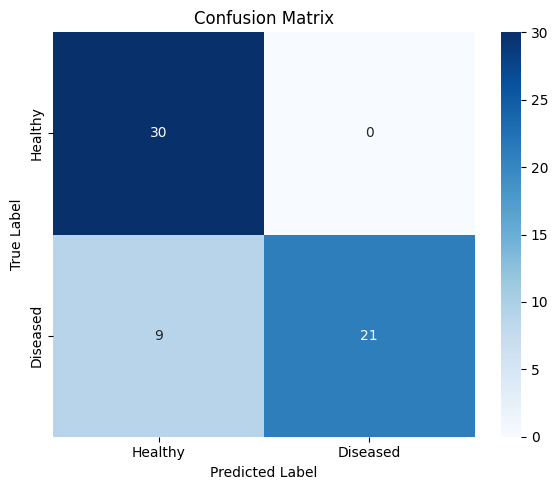


Classification Report:

              precision    recall  f1-score   support

     Healthy       0.77      1.00      0.87        30
    Diseased       1.00      0.70      0.82        30

    accuracy                           0.85        60
   macro avg       0.88      0.85      0.85        60
weighted avg       0.88      0.85      0.85        60



In [15]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

y_pred_prob = best_model.predict(test_ds)

y_pred = (y_pred_prob > 0.5).astype(int).ravel()

y_true = np.concatenate([y for x, y in test_ds], axis=0).ravel()

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Healthy", "Diseased"],
    yticklabels=["Healthy", "Diseased"]
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

print("\nClassification Report:\n")
print(classification_report(y_true, y_pred, target_names=["Healthy", "Diseased"]))